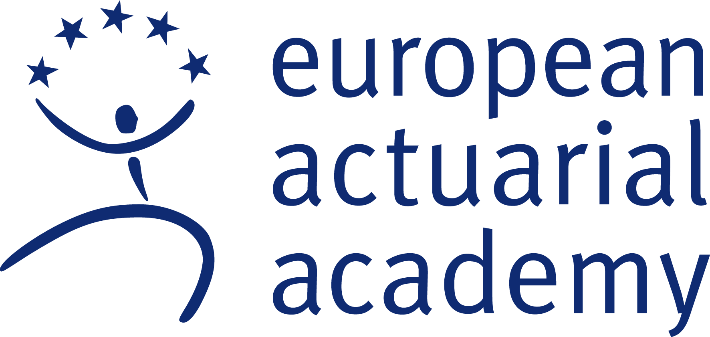

<p style="font-size:17px; text-align:left;"><i>EAA Web Session E0595, GenAI Beyond the Basics: Advanced Concepts for Actuaries, 07 December 2026</i></p>
<p style="font-size:25px; text-align:left; font-weight:bold;">Notebook 4: Fine-Tuning, Teaching a Model Your House Style</p>
<p style="font-size:16px; text-align:left; margin-bottom: 15px;">Dr Simon Hatzesberger<br>Programme slot: 10:35–10:55 CET</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/simonhatzesberger/genai-beyond-the-basics-20261207/blob/main/notebooks/04_fine_tuning.ipynb) &nbsp; Notebook `04_fine_tuning.ipynb` of the repository <https://github.com/simonhatzesberger/genai-beyond-the-basics-20261207>

Fine-tuning continues the training of a pre-trained model on your own examples, so that the desired behaviour is
built into the model rather than repeated in every prompt. This notebook shows two routes on the same actuarial task,
coding motor claims to a house cause-of-loss taxonomy:

* **Part A, provider fine-tuning:** the supervised fine-tuning workflow of OpenAI's API (data preparation, validation,
  job), together with the current status of that platform, which is being wound down.
* **Part B, open-weights fine-tuning:** a real **LoRA** training run on a small open-weights model, on your own
  machine or in Colab, which stays available independently of any provider.

**Contents**
1. [Concept and purpose](#fine-tuning-concept)
2. [Setup](#setup)
3. [Part A: supervised fine-tuning via the OpenAI API](#part-a)
4. [Part B: LoRA fine-tuning of an open-weights model](#part-b)
5. [When to fine-tune, and further resources](#fine-tuning-further-applications-and-resources)

<h1 id="fine-tuning-concept"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
1. Concept and Purpose
</h1>

Fine-tuning adapts a (pre-trained) LLM to your specific domain by continuing training on a curated set of labelled examples. Unlike prompt engineering – where you provide context and examples at inference time – fine-tuning adjusts the model's internal weights, yielding permanent improvements that no longer require repeated context. In this section, we focus on the standard supervised fine-tuning workflow; alternative approaches such as Direct Preference Optimization (DPO) and reinforcement-based methods also exist but are beyond our scope.

By fine-tuning, you effectively teach the model your "language" – whether that's your company's tone, structure and content of reports, complex insurance rules, or the precise interpretation of structured claim data. The result is a model that delivers more relevant, reliable, and efficient outputs in your actuarial context.

#### Why It Matters to Actuaries

* **Regulatory precision** – Fine-tuned models can reproduce mandatory wording (e.g., Solvency II or IFRS 17 disclosures) verbatim, minimizing compliance risks and hallucinations.  
* **Data privacy and efficiency** – Proprietary inputs such as loss triangles or tariff tables are used only during training; inference no longer requires repeated exposure of sensitive data.  
* **Consistent decision-making** – Underwriting assessments or claims triage follow the same trained logic every time, reducing reviewer variability.  
* **Lower cost and latency** – Tailored, fine-tuned models often match the accuracy of much larger general-purpose models, resulting in faster responses and reduced compute costs – critical for production environments.


<div style="background-color: #f2f2f2; border-left: 4px solid #888888; padding-left: 10px; padding-bottom: 1px; padding-top: 6px;">
<p style="font-weight: bold"><b>Note</b></p>
<p style="margin-bottom: 10px;">
Model distillation is a form of fine-tuning in which a compact "student" model is trained on the soft-label outputs of a larger "teacher" model. By learning to reproduce the teacher's probability distributions, the student retains most of the teacher's domain knowledge while operating with significantly lower latency and resource demands.
</p>
</div>

#### Two ways to fine-tune

| | Provider fine-tuning (e.g. OpenAI API) | Open-weights fine-tuning (e.g. LoRA) |
|---|---|---|
| **Where** | provider's platform; you upload data | your machine, Colab or your own cloud |
| **What changes** | the provider trains a copy of its model | you train small adapter matrices next to frozen weights |
| **Effort** | a few API calls; no GPU needed | some ML tooling; a GPU helps |
| **Data** | training data leaves your environment | can stay in-house |
| **Lifetime** | ends when the provider retires the base model or the service | as long as you keep the files |

<div style="background-color: #f2f2f2; border-left: 4px solid #888888; padding-left: 10px; padding-right: 10px; padding-bottom: 1px; padding-top: 6px;">
<p style="font-weight: bold"><b>Status</b></p>

**Status of OpenAI fine-tuning (checked 22 November 2026).** OpenAI is winding down self-serve fine-tuning.
The platform has been closed to new users since 7 May 2026; eligible existing customers can create training jobs
until **6 January 2027**. The base models that support supervised fine-tuning (`gpt-4.1`, `gpt-4.1-mini`, `gpt-4o`,
`gpt-4o-mini`) and the models fine-tuned from them shut down on **14 January 2027**. Part A therefore shows the
workflow, which carries over to other providers, without launching a job. Sources:
<https://developers.openai.com/api/docs/guides/supervised-fine-tuning> and
<https://developers.openai.com/api/docs/deprecations>.

</div>

#### A Three-Step Supervised Fine-Tuning Workflow

**Step 1: Data Preparation**
Collect representative prompt–response pairs that reflect your actuarial use case and format them as **chat-style JSONL** — one `{"messages": [...]}` object per line, with the *assistant* turn as the training target. Favour a small set of *high-quality*, class-balanced examples over a large noisy one, and split them into training and validation subsets. *See the [supervised fine-tuning guide](https://developers.openai.com/api/docs/guides/supervised-fine-tuning).*

**Step 2: Training**
Upload the files with `purpose="fine-tune"` and launch a **supervised** job with `client.fine_tuning.jobs.create(..., method={"type": "supervised", ...})`. Start with the default (`"auto"`) hyperparameters and only nudge `n_epochs` if the model under- or over-fits.

**Step 3: Deployment & Governance**
When the job succeeds it returns a unique fine-tuned model id (`job.fine_tuned_model`). Use that id in your `client.responses.create()` calls, and version- and access-control it like any other production model. Plan for its end of life: a fine-tuned model lives only as long as its base model.

<h1 id="setup"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
2. Setup
</h1>

In [1]:
# ── Setup: run this cell first ───────────────────────────────────────────────────────────────
import os
import subprocess
import sys
import urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_RAW = "https://raw.githubusercontent.com/simonhatzesberger/genai-beyond-the-basics-20261207/main/notebooks/"

import json
from openai import OpenAI


def load_openai_api_key(name: str = "OPENAI_API_KEY", file_path: str = "openai_api_key.txt") -> str | None:
    """Look for the key in Colab Secrets, then in an environment variable, then in a local text file."""
    try:
        from google.colab import userdata  # only available in Colab
        value = userdata.get(name)
        if value:
            return value.strip()
    except Exception:
        pass
    if os.getenv(name):
        return os.getenv(name).strip()
    for candidate in (Path(file_path), Path("..") / file_path):
        if candidate.exists():
            return candidate.read_text(encoding="utf-8").strip()
    return None


api_key = load_openai_api_key()
client = OpenAI(api_key=api_key or "no-key-found")   # the key's value is never printed

MODEL = "gpt-6-luna"           # OpenAI's current small model (checked 22 Nov 2026: no announced shutdown date)
REASONING = {"effort": "low"}  # always set the reasoning effort explicitly (the default is "medium")

print("Running in", "Google Colab" if IN_COLAB else "a local Python " + sys.version.split()[0])
print("OpenAI API key:", "found" if api_key else "NOT found - you can read the saved outputs, but API calls will fail "
      "(see 00_setup_check.ipynb)")
print("Model:", MODEL, "| reasoning effort:", REASONING["effort"])

Running in a local Python 3.13.1
OpenAI API key: found
Model: gpt-6-luna | reasoning effort: low


<h1 id="part-a"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
3. Part A: Supervised Fine-Tuning via the OpenAI API
</h1>

Motor insurers code every loss to a **standardized cause taxonomy** (collision, theft, hail, …) for reserving, pricing, and regulatory reporting. A general-purpose model can already do this, but only if you spell out the full taxonomy and rules in **every** prompt. **Supervised fine-tuning** lets us bake that taxonomy into a smaller, cheaper model, so that at inference time a bare description is enough. The pay-off is **lower latency, lower cost, and more consistent** house-style coding.

We first assemble a tiny, class-balanced training set of `description → cause code` pairs in the chat-JSONL format OpenAI expects.

In [2]:
# The insurer's standardized cause-of-loss taxonomy
CLAIM_CAUSE_CODES = ["COLLISION", "THEFT", "FIRE", "FLOOD", "HAIL",
                     "VANDALISM", "GLASS", "ANIMAL", "STORM", "OTHER"]

SYSTEM_FT = ("You are a claims coder for a motor insurer. "
             "Map the loss description to exactly one house cause code and reply with only the code.")

# (description, code) pairs — in practice these come from historical, adjuster-labelled claims
train_pairs = [
    ("Rear-ended the car in front at a red light.", "COLLISION"),
    ("Skidded on ice and hit the crash barrier.", "COLLISION"),
    ("Car was stolen overnight from the driveway.", "THEFT"),
    ("Thieves broke the lock and drove the vehicle away.", "THEFT"),
    ("Engine caught fire while parked in the garage.", "FIRE"),
    ("Vehicle burnt out after an electrical fault.", "FIRE"),
    ("Flood water rose above the sills and ruined the interior.", "FLOOD"),
    ("Car submerged in a flash flood underpass.", "FLOOD"),
    ("Hailstones dented the roof, bonnet and boot.", "HAIL"),
    ("Golf-ball-sized hail cracked the paintwork.", "HAIL"),
    ("Someone keyed both doors in the car park.", "VANDALISM"),
    ("Wing mirror deliberately snapped off overnight.", "VANDALISM"),
    ("A stone chipped and cracked the windscreen.", "GLASS"),
    ("Rear window shattered, nothing else damaged.", "GLASS"),
    ("A deer ran into the road and I hit it.", "ANIMAL"),
    ("Collided with a wild boar on a country lane.", "ANIMAL"),
    ("A falling tree branch dented the roof in a gale.", "STORM"),
    ("High winds blew a fence panel onto the car.", "STORM"),
]
val_pairs = [
    ("Reversed into a bollard in the car park.", "COLLISION"),
    ("Catalytic converter cut out and stolen.", "THEFT"),
    ("Hail dented every horizontal panel.", "HAIL"),
    ("Windscreen cracked by a flying stone on the motorway.", "GLASS"),
]

def to_example(desc, code):
    return {"messages": [
        {"role": "system", "content": SYSTEM_FT},
        {"role": "user", "content": desc},
        {"role": "assistant", "content": code},
    ]}

def write_jsonl(path, pairs):
    with open(path, "w", encoding="utf-8") as f:
        for desc, code in pairs:
            f.write(json.dumps(to_example(desc, code)) + "\n")

write_jsonl("ft_claim_cause_train.jsonl", train_pairs)
write_jsonl("ft_claim_cause_val.jsonl", val_pairs)
print(f"Wrote {len(train_pairs)} training and {len(val_pairs)} validation examples.")

Wrote 18 training and 4 validation examples.


Each line is one training example. The **assistant** message is the target the model learns to reproduce; the **system** message is the same instruction you would use at inference. Let us validate the file and inspect one record.

In [3]:
def validate_chat_jsonl(path):
    n = 0
    with open(path, encoding="utf-8") as f:
        for line in f:
            obj = json.loads(line)
            roles = [m["role"] for m in obj["messages"]]
            assert roles[-1] == "assistant", "last turn must be the assistant target"
            n += 1
    return n

n_train = validate_chat_jsonl("ft_claim_cause_train.jsonl")
print(f"ft_claim_cause_train.jsonl is valid ({n_train} examples).")
print("\nExample record:")
print(json.dumps(json.loads(open("ft_claim_cause_train.jsonl", encoding="utf-8").readline()), indent=2))

ft_claim_cause_train.jsonl is valid (18 examples).

Example record:
{
  "messages": [
    {
      "role": "system",
      "content": "You are a claims coder for a motor insurer. Map the loss description to exactly one house cause code and reply with only the code."
    },
    {
      "role": "user",
      "content": "Rear-ended the car in front at a red light."
    },
    {
      "role": "assistant",
      "content": "COLLISION"
    }
  ]
}


**Before fine-tuning**, the base model can solve the task only if we hand it the full taxonomy in the prompt every
single time. Here is that baseline with our default model, on the four validation examples:

In [4]:
baseline_instructions = SYSTEM_FT + " Choose exactly one of: " + ", ".join(CLAIM_CAUSE_CODES) + "."

for desc, expected in val_pairs:
    resp = client.responses.create(
        model=MODEL, reasoning={"effort": "none"},
        instructions=baseline_instructions, input=desc,
    )
    got = resp.output_text.strip()
    print(f"[{'OK' if got == expected else 'DIFF'}] {desc}\n      -> {got} (expected {expected})")

[OK] Reversed into a bollard in the car park.
      -> COLLISION (expected COLLISION)


[OK] Catalytic converter cut out and stolen.
      -> THEFT (expected THEFT)


[OK] Hail dented every horizontal panel.
      -> HAIL (expected HAIL)


[OK] Windscreen cracked by a flying stone on the motorway.
      -> GLASS (expected GLASS)


**Launching the fine-tuning job** uses the modern *supervised* method of the fine-tuning API. We upload the files with `purpose="fine-tune"`, then create the job with `method={"type": "supervised", ...}` on a fine-tunable base model. Because OpenAI's fine-tuning is being wound down (see the status box above), the flag stays off in this edition. Training is a paid, asynchronous job, so it is **guarded by a flag** below — set `RUN_FINE_TUNING = True` to actually run it.

In [5]:
RUN_FINE_TUNING = False                      # set True to upload the data and launch a (paid) job
FT_BASE_MODEL = "gpt-4.1-mini-2025-04-14"     # fine-tunable until 6 Jan 2027; shuts down 14 Jan 2027

if RUN_FINE_TUNING:
    train_file = client.files.create(file=open("ft_claim_cause_train.jsonl", "rb"), purpose="fine-tune")
    val_file = client.files.create(file=open("ft_claim_cause_val.jsonl", "rb"), purpose="fine-tune")

    job = client.fine_tuning.jobs.create(
        training_file=train_file.id,
        validation_file=val_file.id,
        model=FT_BASE_MODEL,
        method={"type": "supervised", "supervised": {"hyperparameters": {"n_epochs": "auto"}}},
        suffix="eaa-claim-cause",
    )
    print("Launched fine-tuning job:", job.id)
    # Poll with client.fine_tuning.jobs.retrieve(job.id).status; when "succeeded",
    # the model id is in .fine_tuned_model
else:
    print("RUN_FINE_TUNING is False - no job launched. The cell shows the supervised fine-tuning API pattern.")

RUN_FINE_TUNING is False - no job launched. The cell shows the supervised fine-tuning API pattern.


Once a job **succeeds**, you call the fine-tuned model exactly like any other, but now a bare description
suffices, with no taxonomy in the prompt:

```python
ft_model = job.fine_tuned_model   # e.g. 'ft:gpt-4.1-mini-2025-04-14:org::abc123'
resp = client.responses.create(model=ft_model, input="A deer ran into the road and I hit it.")
print(resp.output_text)            # -> ANIMAL
```

The same three steps (prepare chat-style JSONL, upload, train; then call the new model ID) apply at other providers
that offer fine-tuning, for example on Microsoft Azure, Google Vertex AI or AWS Bedrock.

<h1 id="part-b"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
4. Part B: LoRA Fine-Tuning of an Open-Weights Model
</h1>

Full fine-tuning updates every weight of a model, which for anything useful needs a serious GPU. **LoRA**
(Low-Rank Adaptation) freezes the original weights and trains a small pair of low-rank matrices alongside selected
layers: a tiny fraction of the parameters, small enough that the training run below finishes on a laptop CPU in
about a minute.

The model is **`Qwen/Qwen2.5-0.5B-Instruct`**, an open-weights model with 0.5 billion parameters (Apache-2.0 licence,
about 1 GB to download on first use). We train it on the **same 18 claim descriptions** as in Part A and evaluate it
on the same four validation examples. No API key and no provider are involved from here on.

**Where to run it.** Training runs automatically when a GPU is available: in Colab, choose *Runtime → Change
runtime type → T4 GPU* (free) before *Run all*. On a CPU the same training can take from a few minutes to much
longer, depending on the machine, so it is switched off there by default (`RUN_LORA`). Locally, install the optional
packages once with `pip install -r requirements-lora.txt` (PyTorch, Transformers, PEFT, Datasets).

In [6]:
import time
import warnings

try:
    import torch
    from datasets import Dataset, disable_progress_bars
    from peft import LoraConfig, get_peft_model
    from transformers import (AutoModelForCausalLM, AutoTokenizer, DataCollatorForLanguageModeling,
                              Trainer, TrainingArguments)
except ImportError as exc:
    raise ImportError("Part B needs PyTorch, Transformers, PEFT and Datasets: "
                      "pip install -r requirements-lora.txt (preinstalled in Colab)") from exc

warnings.filterwarnings("ignore")   # housekeeping notices only
disable_progress_bars()
torch.manual_seed(0)

RUN_LORA = torch.cuda.is_available()   # trains automatically on a GPU; set to True to train on a CPU as well
device = "cuda" if torch.cuda.is_available() else "cpu"
BASE_MODEL = "Qwen/Qwen2.5-0.5B-Instruct"

if RUN_LORA:
    tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
    model = AutoModelForCausalLM.from_pretrained(BASE_MODEL).to(device)
    print(f"Loaded {BASE_MODEL}: {sum(p.numel() for p in model.parameters()):,} parameters, on {device.upper()}.")
else:
    print("[skipped] Part B trains only with a GPU (in Colab: Runtime -> Change runtime type -> T4 GPU), "
          "or set RUN_LORA = True to train on this CPU.")

[skipped] Part B trains only with a GPU (in Colab: Runtime -> Change runtime type -> T4 GPU), or set RUN_LORA = True to train on this CPU.


#### Before training

We use a deliberately bare prompt, `Claim: … / Cause code:`, **without** the taxonomy, which is exactly the situation
fine-tuning is meant to fix. Greedy decoding (no sampling) makes the answers reproducible.

In [7]:
def build_prompt(description: str) -> str:
    return f"Claim: {description}\nCause code:"


def answer(description: str, max_new_tokens: int = 12) -> str:
    inputs = tokenizer(build_prompt(description), return_tensors="pt").to(device)
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                                pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()


if RUN_LORA:
    before = {desc: answer(desc) for desc, _ in val_pairs}
    for (desc, expected) in val_pairs:
        print(f"{desc}\n   BEFORE: {before[desc]!r}   (expected {expected})")

#### The LoRA adapter

`LoraConfig` says where the adapter goes and how large it is: rank-8 matrices attached to the attention projections
of every layer. `get_peft_model` freezes everything else, and `print_trainable_parameters()` reports how much of the
model the training run will actually touch.

In [8]:
lora_config = LoraConfig(r=8, lora_alpha=16, lora_dropout=0.0,
                         target_modules=["q_proj", "v_proj"], task_type="CAUSAL_LM")
if RUN_LORA:
    model = get_peft_model(model, lora_config)
    model.print_trainable_parameters()

#### The training run

Eight passes over the 18 examples, batches of four, sequences padded to 40 tokens; `logging_steps` prints the loss
as training proceeds, so you can watch it fall.

In [9]:
def train_lora():
    rows = [{"text": build_prompt(desc) + f" {code_}" + tokenizer.eos_token} for desc, code_ in train_pairs]
    dataset = Dataset.from_list(rows).map(
        lambda batch: tokenizer(batch["text"], truncation=True, padding="max_length", max_length=40),
        batched=True, remove_columns=["text"],
    )
    trainer = Trainer(
        model=model,
        args=TrainingArguments(
            output_dir="lora_claim_cause", num_train_epochs=8, per_device_train_batch_size=4,
            learning_rate=2e-3, logging_steps=5, save_strategy="no", report_to="none",
            disable_tqdm=True, use_cpu=(device == "cpu"), seed=0,
        ),
        train_dataset=dataset,
        data_collator=DataCollatorForLanguageModeling(tokenizer, mlm=False),
    )
    start = time.time()
    trainer.train()
    losses = [e["loss"] for e in trainer.state.log_history if "loss" in e]
    print(f"\nTrained in {time.time() - start:.0f} seconds; loss {losses[0]:.2f} -> {losses[-1]:.2f}.")


if RUN_LORA:
    train_lora()

#### After training

The same four validation descriptions, never seen in training, the same greedy decoding, the same bare prompt:

In [10]:
if RUN_LORA:
    model.eval()
    hits = 0
    for desc, expected in val_pairs:
        after = answer(desc)
        hits += after == expected
        print(f"{desc}\n   BEFORE: {before[desc]!r}\n   AFTER : {after!r}   (expected {expected})")
    print(f"\nExact matches after training: {hits} of {len(val_pairs)}")

#### What actually happened

Read the before/after lines carefully. Before training, the small model typically answers in free text, invents a
category of its own or does not stop where it should, because nothing tells it that "Cause code:" is followed by one
code from a fixed list and then silence. After training on 18 examples, it answers with codes from the house taxonomy
in the house format.

That is a real improvement, but mostly in **format and vocabulary**, and four validation examples are a
demonstration, not an evaluation. A proper evaluation needs a held-out set of a few hundred labelled claims, a
confusion matrix, and a comparison with the simpler alternatives: a general model with the taxonomy in the prompt
(Part A's baseline) and a schema with a closed list of codes (notebook 02). On small data, fine-tuning reliably buys
**consistency**, and only rarely **competence**.

<h1 id="fine-tuning-further-applications-and-resources"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
5. When to Fine-Tune, and Further Resources
</h1>

#### When to fine-tune, and when not

* **Try prompting, Structured Outputs and RAG first.** They are cheaper, faster to change and easier to audit.
* **Fine-tune** when a narrow task is repeated at high volume, the output format or style must be very consistent, the
  instructions would otherwise be very long, or a small (local) model must reach the quality of a larger one.
* **Do not fine-tune to add facts.** Knowledge that changes (tariffs, regulation, reports) belongs in a retrieval
  layer (notebook 05), not in the weights.
* **Treat a fine-tuned model as a model**: version the training data, document the evaluation, and plan for the end of
  life of the base model.

#### Additional Actuarial Applications for Fine-Tuning

- **Consistent and Efficient Report Generation** – Fine-tuned models leverage historical documents and associated numerical data—from actuarial reserves and risk assessments to technical documentation and sustainability reports—to reliably produce new reports or specific report sections. Users simply input updated figures, and the model automatically generates consistent, compliant, and professionally styled outputs, significantly streamlining reporting workflows.
- **Customer Service Automation** – Chatbots trained on policy documentation and FAQs accurately handle customer inquiries on coverage and premiums, providing consistent responses in the company's style and voice.
- **Fraud Detection & Claims Triage** – Models fine-tuned on historical fraud cases rapidly flag suspicious claims or route complex cases to specialists, improving efficiency and accuracy of fraud detection.
- **Automated Claims Assessment** – Fine-tuned models quickly categorize claims based on damage descriptions, photos, and adjuster notes, streamlining settlements and significantly reducing processing times.

#### Further Reading and Resources on Fine-Tuning

1. [Supervised fine-tuning — OpenAI API guide](https://developers.openai.com/api/docs/guides/supervised-fine-tuning) (including the wind-down timeline)
2. [Hu et al. (2021): LoRA — Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685)
3. [Hugging Face PEFT documentation](https://huggingface.co/docs/peft)
4. [Qwen2.5-0.5B-Instruct model card](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct)
5. [Hatzesberger & Nonneman (2026): Advanced applications of generative AI in actuarial science: case studies beyond ChatGPT, *European Actuarial Journal* 16(2):481–523](https://doi.org/10.1007/s13385-026-00464-9), including a vision fine-tuning case study on vehicle damage photos (preprint: [arXiv:2506.18942](https://arxiv.org/abs/2506.18942))